# Экзаменационная задача №14. Оценка ценности информации для инвестиционного проекта

**Дисциплина:** Экономика информатизации, лекция №15
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №14: ОЦЕНКА ЦЕННОСТИ ИНФОРМАЦИИ ДЛЯ ИНВЕСТИЦИОННОГО ПРОЕКТА
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №15)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Перед запуском проекта можно заказать исследование (рынка или технологии) за 5 млн руб. Оно повышает шанс успеха
с 50 % до 80 %. Нужно решить, стоит ли за это платить. Это классическая задача о **ценности информации**:
информация стоит ровно столько, насколько она улучшает ожидаемый результат.

**Цель:** посчитать ожидаемую прибыль без исследования и с ним, ценность информации и принять решение с учётом рисков.

Тема лекции №15: решения в условиях неопределённости, ожидаемая стоимость, ценность информации (EVSI, EVPI),
дерево решений, отношение к риску.

## 2. Исходные данные

In [2]:
p_no, p_yes = 0.50, 0.80     # вероятность успеха без исследования / с исследованием
profit = 30.0                 # прибыль при успехе, млн руб.
loss_fail = 0.0               # результат при неудаче (в условии не задан → 0)
research_cost = 5.0           # стоимость исследования, млн руб. (оплачивается в момент 0)
H, r = 3, 0.10                # горизонт, лет; ставка
pd.DataFrame({"Параметр": ["P(успех) без исследования", "P(успех) с исследованием", "Прибыль при успехе", "Результат при неудаче",
                           "Стоимость исследования", "Горизонт", "Ставка"],
              "Значение": ["50%", "80%", "30 млн", "0 (не задан)", "5 млн", "3 года", "10%"]})

,Параметр,Значение
0,P(успех) без исследования,50%
1,P(успех) с исследованием,80%
2,Прибыль при успехе,30 млн
3,Результат при неудаче,0 (не задан)
4,Стоимость исследования,5 млн
5,Горизонт,3 года
6,Ставка,10%


**Когда приходят деньги.** Прибыль 30 млн руб. это результат проекта за 3 года. Смотрим два варианта:
(А) вся прибыль в конце 3-го года (основной, осторожный); (Б) по 10 млн руб. каждый год.
Исследование оплачиваем сразу (t = 0), его не дисконтируем.
Что будет при неудаче, в условии не сказано. Принимаем 0 (проект просто ничего не приносит),
а вариант с убытком проверяем в анализе рисков.

## 3. Математическая модель

$$E[\Pi_{без}] = p_0\cdot\Pi\cdot DF + (1-p_0)\cdot L\cdot DF,\qquad E[\Pi_{с}] = p_1\cdot\Pi\cdot DF + (1-p_1)\cdot L\cdot DF - C_{иссл}$$
$$\text{Ценность информации (EVSI)} = (p_1-p_0)(\Pi - L)\cdot DF,\qquad \text{исследовать, если } EVSI > C_{иссл}$$
где $DF = 1/(1+r)^3 = 0{,}7513$ для варианта А или $DF = \tfrac{1}{3}\sum_{t=1}^3 (1+r)^{-t} = 0{,}829$ для варианта Б.

Минимальный шанс успеха после исследования, при котором оно окупается: $p_1^* = p_0 + \dfrac{C_{иссл}}{(\Pi-L)\cdot DF}$.

Для сравнения **ценность совершенной информации** (EVPI): если бы заранее точно знали, получится ли проект,
неудачный можно было бы не запускать: $EVPI = (1-p_0)\cdot\max(0, -L)\cdot DF$.

## 4. Реализация расчёта

In [3]:
DF_A = 1 / (1 + r) ** H
DF_B = annuity_factor(r, H) / H
def evaluate(DF, p0=p_no, p1=p_yes, P=profit, L=loss_fail, C=research_cost):
    e_no = (p0 * P + (1 - p0) * L) * DF
    e_yes = (p1 * P + (1 - p1) * L) * DF - C
    evsi = (p1 - p0) * (P - L) * DF
    return {"E[прибыль] без исследования": e_no, "E[прибыль] с исследованием (за вычетом 5 млн)": e_yes,
            "Ценность информации EVSI": evsi, "Чистая ценность (EVSI − стоимость)": evsi - C,
            "Пороговая p₁*": p0 + C / ((P - L) * DF), "Решение": "исследовать" if evsi > C else "не исследовать"}

undiscounted = evaluate(1.0)
table = pd.DataFrame({"Без дисконтирования": undiscounted, "А: прибыль в конце 3-го года": evaluate(DF_A),
                      "Б: по 10 млн в год": evaluate(DF_B)})
print(f"DF_A = {DF_A:.4f};  DF_B = {DF_B:.4f}")
table

DF_A = 0.7513;  DF_B = 0.8290


,Без дисконтирования,А: прибыль в конце 3-го года,Б: по 10 млн в год
E[прибыль] без исследования,15.00,11.27,12.43
E[прибыль] с исследованием (за вычетом 5 млн),19.00,13.03,14.89
Ценность информации EVSI,9.00,6.76,7.46
Чистая ценность (EVSI − стоимость),4.00,1.76,2.46
Пороговая p₁*,0.67,0.72,0.70
Решение,исследовать,исследовать,исследовать


### 4.1. Анализ рисков

In [4]:
# Распределение результата (вариант А): дисперсия и вероятность убытка
def risk(p, C, L=loss_fail, DF=DF_A):
    outcomes = np.array([profit * DF - C, L * DF - C]); probs = np.array([p, 1 - p])
    mean = outcomes @ probs; sd = np.sqrt(((outcomes - mean) ** 2) @ probs)
    return {"Ожидание, млн": mean, "Ст. отклонение, млн": sd, "Коэфф. вариации": sd / mean,
            "P(результат ≤ 0)": probs[outcomes <= 0].sum(), "Худший исход, млн": outcomes.min()}
rk = pd.DataFrame({"Без исследования": risk(p_no, 0), "С исследованием": risk(p_yes, research_cost)})
display(rk.round(3))

# Чувствительность решения к ключевым параметрам
sens = []
for p1 in [0.6, 0.65, 0.7, 0.75, 0.8, 0.9]:
    sens.append({"Параметр": "p₁ после исследования", "Значение": f"{p1:.0%}", "Чистая ценность, млн": evaluate(DF_A, p1=p1)["Чистая ценность (EVSI − стоимость)"]})
for P in [15, 20, 30, 40]:
    sens.append({"Параметр": "Прибыль при успехе", "Значение": f"{P} млн", "Чистая ценность, млн": evaluate(DF_A, P=P)["Чистая ценность (EVSI − стоимость)"]})
for L in [0, -10, -20]:
    sens.append({"Параметр": "Результат при неудаче", "Значение": f"{L} млн", "Чистая ценность, млн": evaluate(DF_A, L=L)["Чистая ценность (EVSI − стоимость)"]})
for rr in [0.05, 0.10, 0.20]:
    sens.append({"Параметр": "Ставка", "Значение": f"{rr:.0%}", "Чистая ценность, млн": evaluate(1 / (1 + rr) ** H)["Чистая ценность (EVSI − стоимость)"]})
sens = pd.DataFrame(sens); sens["Решение"] = np.where(sens["Чистая ценность, млн"] > 0, "исследовать", "не исследовать")
sens.round(2)

,Без исследования,С исследованием
"Ожидание, млн",11.27,13.03
"Ст. отклонение, млн",11.27,9.02
Коэфф. вариации,1.00,0.69
P(результат ≤ 0),0.50,0.20
"Худший исход, млн",0.00,-5.00


,Параметр,Значение,"Чистая ценность, млн",Решение
0,p₁ после исследования,60%,-2.75,не исследовать
1,p₁ после исследования,65%,-1.62,не исследовать
2,p₁ после исследования,70%,-0.49,не исследовать
3,p₁ после исследования,75%,0.63,исследовать
4,p₁ после исследования,80%,1.76,исследовать
5,p₁ после исследования,90%,4.02,исследовать
6,Прибыль при успехе,15 млн,-1.62,не исследовать
7,Прибыль при успехе,20 млн,-0.49,не исследовать
8,Прибыль при успехе,30 млн,1.76,исследовать
9,Прибыль при успехе,40 млн,4.02,исследовать


In [5]:
# Ценность совершенной информации при возможном убытке
for L in [0, -10, -20]:
    evpi = (1 - p_no) * max(0, -L) * DF_A
    print(f"Убыток при неудаче {L:>4} млн → EVPI = {evpi:.2f} млн руб.")

Убыток при неудаче    0 млн → EVPI = 0.00 млн руб.
Убыток при неудаче  -10 млн → EVPI = 3.76 млн руб.
Убыток при неудаче  -20 млн → EVPI = 7.51 млн руб.


## 5. Визуализация результатов

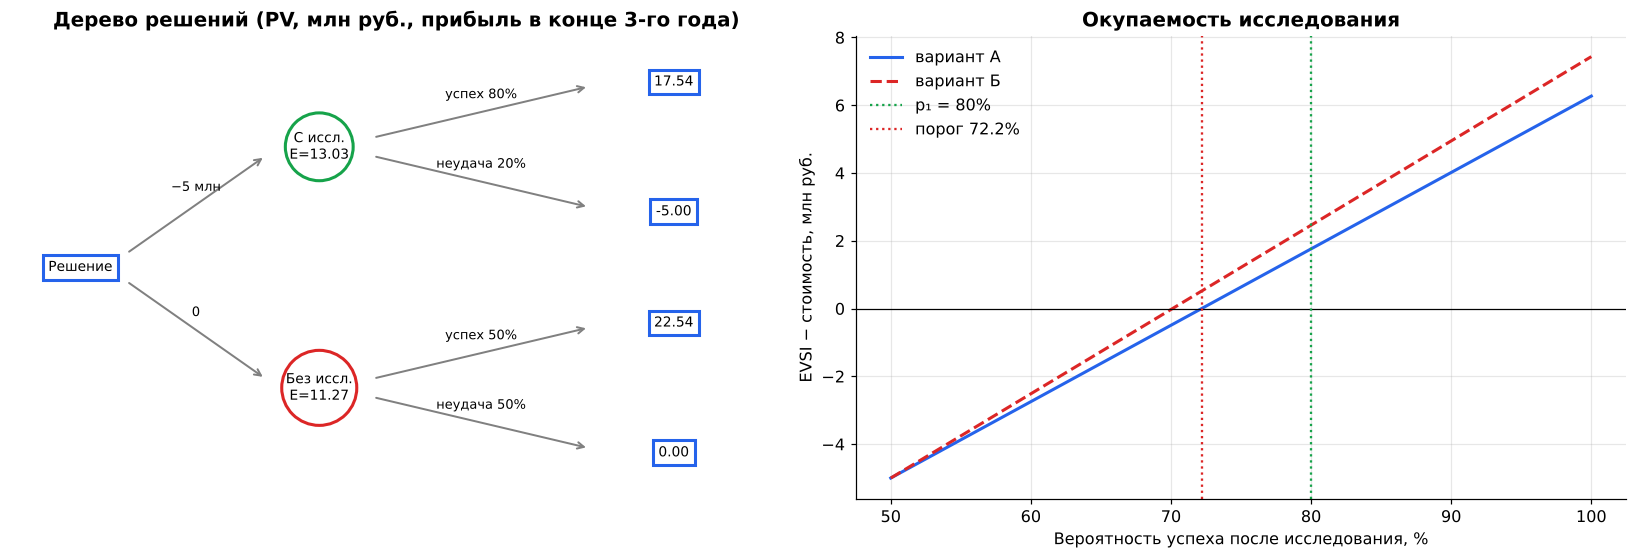

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ax = axes[0]; ax.axis("off"); ax.set_xlim(0, 10); ax.set_ylim(0, 10)
def node(x, y, txt, shape="s", c=PALETTE[0]):
    box = dict(boxstyle="square,pad=0.4" if shape == "s" else "circle,pad=0.3", fc="white", ec=c, lw=2)
    ax.text(x, y, txt, ha="center", va="center", fontsize=9, bbox=box)
def edge(x1, y1, x2, y2, txt):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", lw=1.3, color="gray"))
    ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.3, txt, fontsize=8.5, ha="center")
e = evaluate(DF_A)
node(0.9, 5, "Решение", "s")
node(4, 7.6, f"С иссл.\nE={e['E[прибыль] с исследованием (за вычетом 5 млн)']:.2f}", "c", PALETTE[2])
node(4, 2.4, f"Без иссл.\nE={e['E[прибыль] без исследования']:.2f}", "c", PALETTE[1])
edge(1.5, 5.3, 3.3, 7.4, "−5 млн"); edge(1.5, 4.7, 3.3, 2.6, "0")
for y0, p, c in [(7.6, p_yes, PALETTE[2]), (2.4, p_no, PALETTE[1])]:
    cost = research_cost if p == p_yes else 0
    edge(4.7, y0 + 0.2, 7.5, y0 + 1.3, f"успех {p:.0%}"); node(8.6, y0 + 1.4, f"{profit*DF_A - cost:.2f}")
    edge(4.7, y0 - 0.2, 7.5, y0 - 1.3, f"неудача {1-p:.0%}"); node(8.6, y0 - 1.4, f"{loss_fail*DF_A - cost:.2f}")
ax.set_title("Дерево решений (PV, млн руб., прибыль в конце 3-го года)")
ax = axes[1]
p1s = np.linspace(0.5, 1, 100)
ax.plot(p1s * 100, [evaluate(DF_A, p1=p)["Чистая ценность (EVSI − стоимость)"] for p in p1s], lw=2, label="вариант А")
ax.plot(p1s * 100, [evaluate(DF_B, p1=p)["Чистая ценность (EVSI − стоимость)"] for p in p1s], lw=2, ls="--", label="вариант Б")
ax.axhline(0, color="black", lw=0.8); ax.axvline(80, color=PALETTE[2], ls=":", label="p₁ = 80%")
ax.axvline(evaluate(DF_A)["Пороговая p₁*"] * 100, color=PALETTE[1], ls=":", label=f"порог {evaluate(DF_A)['Пороговая p₁*']:.1%}")
ax.set_xlabel("Вероятность успеха после исследования, %"); ax.set_ylabel("EVSI − стоимость, млн руб.")
ax.set_title("Окупаемость исследования"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **Без дисконтирования:** без исследования ожидаемая прибыль 15 млн руб., с исследованием 24 млн руб.
  Ценность информации 9 млн руб. больше цены 5 млн руб., исследование выгодно, чистый выигрыш 4 млн руб.
- **С дисконтированием (10 %, 3 года):** ценность информации падает примерно до 6,8 млн руб. (вариант А) или 7,5 млн руб.
  (вариант Б), но всё равно больше цены исследования. Чистый выигрыш 1,8–2,5 млн руб. **Решение: исследовать.**
  Важно: платим за исследование сейчас, а выгода приходит через годы. Без дисконтирования выигрыш завышается
  больше чем вдвое (4,0 против 1,8 млн руб.).
- **Запас небольшой:** исследование окупается, только если поднимает шанс успеха хотя бы до 72 % (обещано 80 %).
  Если реальный эффект окажется меньше, решение меняется.
- **Риск:** исследование снижает шанс нулевого результата с 50 % до 20 % и уменьшает разброс. То есть одновременно
  растёт ожидаемый результат и падает риск. Для осторожного инвестора это ещё один аргумент «за».
- **Особенность условия:** при неудаче результат 0, убытка нет. Поэтому *совершенная* информация об исходе здесь ничего не стоит
  (EVPI = 0): знание «проект провалится» не помогает ничего сэкономить. Исследование полезно не как прогноз,
  а как **улучшение проекта** (оно повышает шанс успеха). Если бы неудача давала убыток, информация была бы ценна ещё и тем,
  что позволяет отказаться от проекта.

## 7. Выводы и рекомендации

1. **Заказывать исследование:** ожидаемый выигрыш около 1,8 млн руб. (PV) при осторожном допущении о сроках прибыли,
   плюс шанс неудачи падает с 50 % до 20 %.
2. Договор на исследование заключать с **измеримым результатом**: оно окупается, только если поднимает шанс успеха выше 72 %.
   От исследователя стоит потребовать обоснования этого эффекта.
3. Рассмотреть **исследование по этапам** (пилот за 1–2 млн руб. с возможностью продолжить), чтобы не переплатить за информацию.
4. Если при неудаче проект даёт убыток, исследование ещё ценнее. Если прибыль при успехе окажется ниже 22 млн руб.
   или ставка выше 20 %, решение надо пересчитать (запас маленький).